In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
from pathlib import Path

paths = [
    Path("../PR1/dataset.csv"),
    Path("PR1/dataset.csv")
]

dataset_path = next((p for p in paths if p.is_file()), None)

if dataset_path is None:
    raise FileNotFoundError("Не найден PR1/dataset.csv")

df = pd.read_csv(dataset_path)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
print("Информация о данных:")
df.info()

print("\nСтатистика:")
display(df.describe())

print("\nТипы столбцов:")
display(df.dtypes.to_frame("Тип данных"))

Информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness  

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000



Типы столбцов:


,Тип данных
Unnamed: 0,int64
track_id,str
artists,str
album_name,str
track_name,str
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64


In [4]:
print("Пропуски по столбцам:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

print("\nПроцент пропусков:")
missing_percent = df.isnull().mean() * 100
print(missing_percent.round(2))

Пропуски по столбцам:
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Количество дубликатов:
0

Процент пропусков:
Unnamed: 0          0.0
track_id            0.0
artists             0.0
album_name          0.0
track_name          0.0
popularity          0.0
duration_ms         0.0
explicit            0.0
danceability        0.0
energy              0.0
key                 0.0
loudness            0.0
mode                0.0
speechiness         0.0
acousticness        0.0
instrumentalness    0.0
liveness            0.0
valence             0.0
tempo               0.0
t

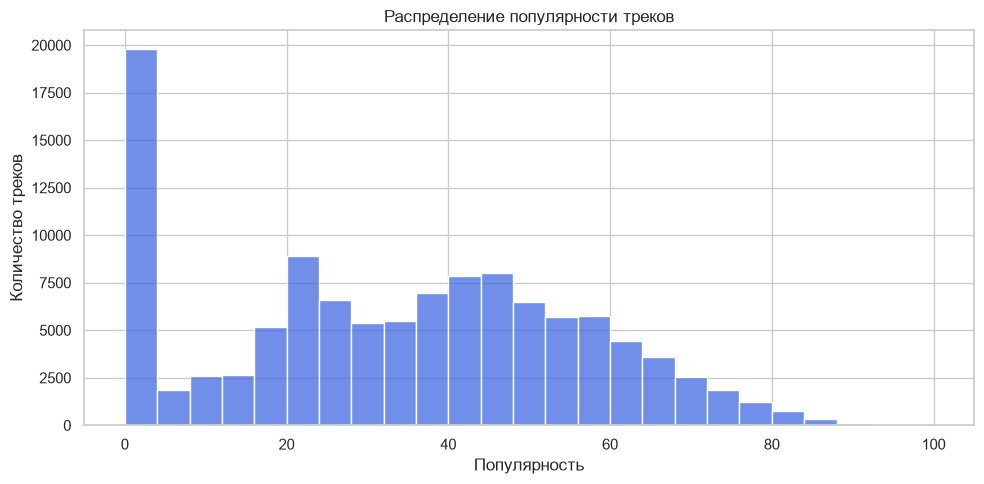

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="popularity",
    bins=25,
    color="royalblue"
)

plt.title("Распределение популярности треков")
plt.xlabel("Популярность")
plt.ylabel("Количество треков")
plt.tight_layout()
plt.show()

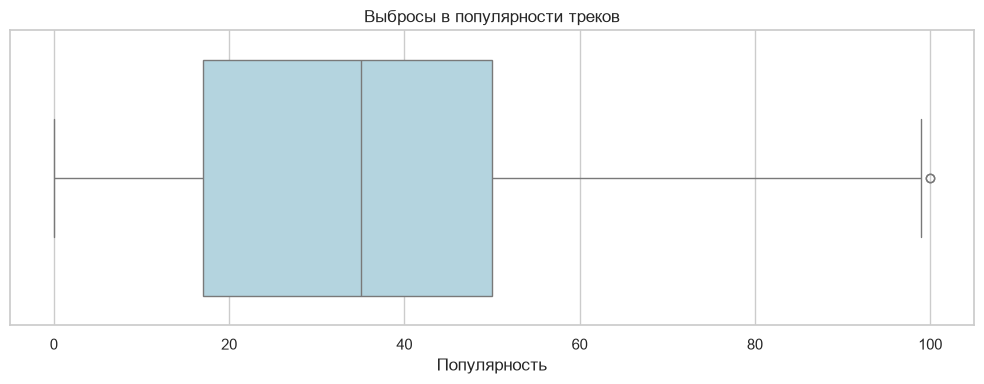

In [6]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="popularity",
    color="lightblue"
)

plt.title("Выбросы в популярности треков")
plt.xlabel("Популярность")
plt.tight_layout()
plt.show()

In [7]:
q1 = df["popularity"].quantile(0.25)
q3 = df["popularity"].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[
    (df["popularity"] < lower) |
    (df["popularity"] > upper)
]

print("Нижняя граница:", lower)
print("Верхняя граница:", upper)
print("Потенциальных выбросов:", len(outliers))

Нижняя граница: -32.5
Верхняя граница: 99.5
Потенциальных выбросов: 2


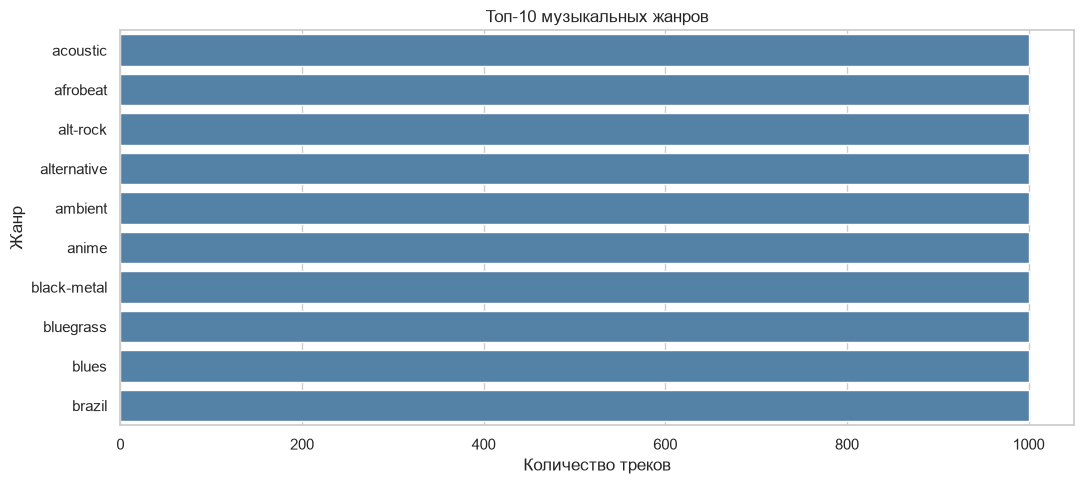

In [8]:
top_genres = df["track_genre"].value_counts().head(10)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    color="steelblue"
)

plt.title("Топ-10 музыкальных жанров")
plt.xlabel("Количество треков")
plt.ylabel("Жанр")
plt.tight_layout()
plt.show()

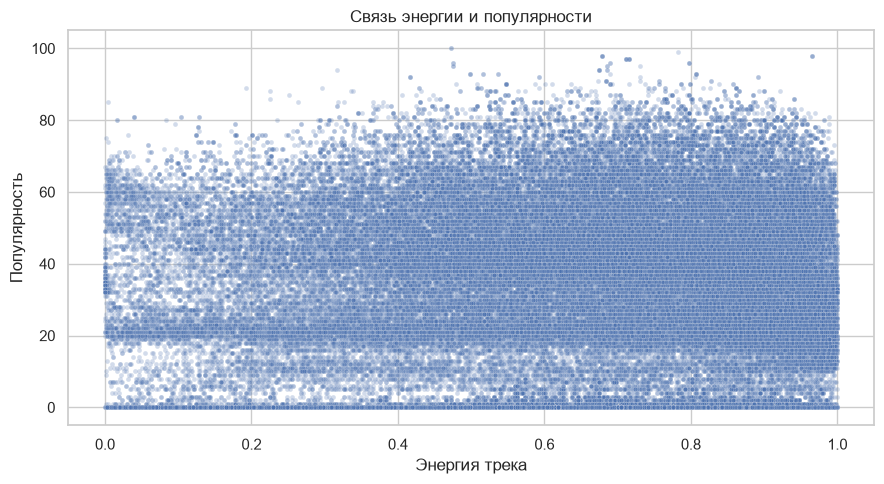

Корреляция: 0.0010561362996985052


In [9]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="energy",
    y="popularity",
    alpha=0.25,
    s=12
)

plt.title("Связь энергии и популярности")
plt.xlabel("Энергия трека")
plt.ylabel("Популярность")
plt.tight_layout()
plt.show()

print(
    "Корреляция:",
    df["energy"].corr(df["popularity"])
)

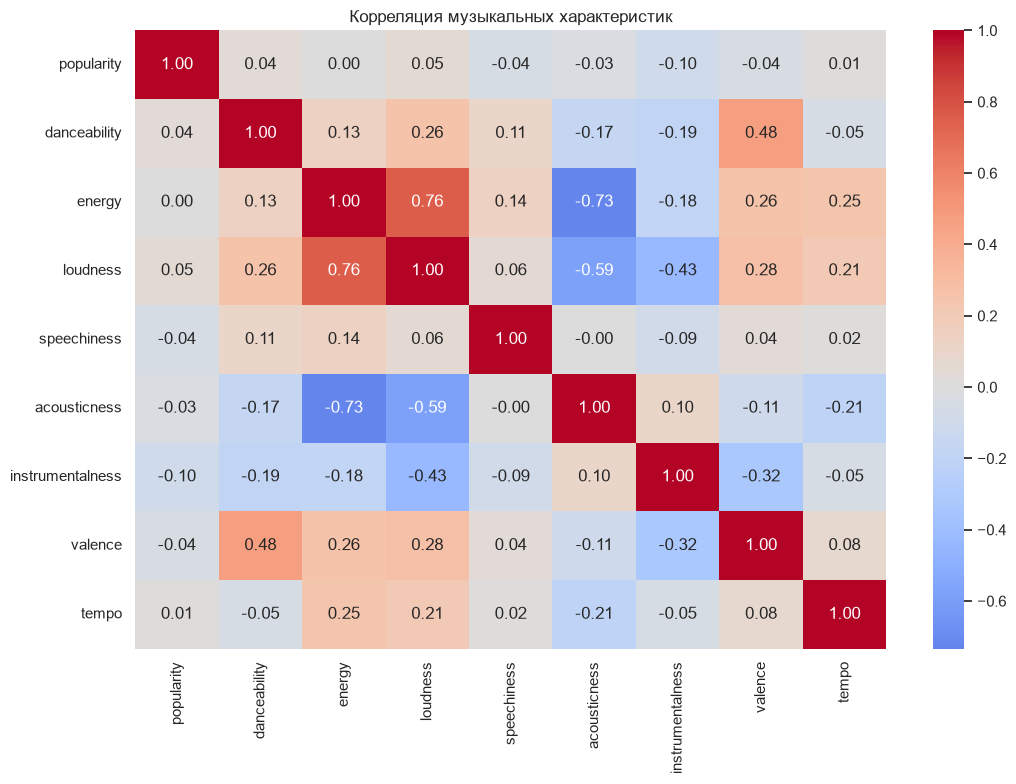

In [10]:
features = [
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "valence",
    "tempo"
]

corr = df[features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Корреляция музыкальных характеристик")
plt.tight_layout()
plt.show()

In [11]:
genre_counts = df["track_genre"].value_counts()

print("Количество жанров:", genre_counts.size)

print("\nНаименее распространённые жанры:")
print(genre_counts.tail(10))

print("\nСамый распространённый жанр:")
print(genre_counts.head(1))

Количество жанров: 114

Наименее распространённые жанры:
track_genre
spanish        1000
study          1000
swedish        1000
synth-pop      1000
tango          1000
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, dtype: int64

Самый распространённый жанр:
track_genre
acoustic    1000
Name: count, dtype: int64


In [12]:
print("ИТОГИ АНАЛИЗА")
print("-----------------------------")

print("Строк:", df.shape[0])
print("Столбцов:", df.shape[1])
print("Пропусков:", df.isnull().sum().sum())
print("Дубликатов:", df.duplicated().sum())
print("Потенциальных выбросов популярности:", len(outliers))
print("Количество жанров:", df["track_genre"].nunique())

print("\nПопулярность:")
print("Средняя:", round(df["popularity"].mean(), 2))
print("Медиана:", df["popularity"].median())

print("\nСамая сильная корреляция с популярностью:")

pop_corr = corr["popularity"].drop("popularity").dropna()

if not pop_corr.empty:
    strongest = pop_corr.abs().idxmax()
    print(
        strongest,
        "—",
        round(pop_corr[strongest], 3)
    )

ИТОГИ АНАЛИЗА
-----------------------------
Строк: 114000
Столбцов: 21
Пропусков: 3
Дубликатов: 0
Потенциальных выбросов популярности: 2
Количество жанров: 114

Популярность:
Средняя: 33.24
Медиана: 35.0

Самая сильная корреляция с популярностью:
instrumentalness — -0.095


## Итоги EDA

В этой работе я проверил Spotify Dataset и изучил его характеристики.

**Что проверил:**
- Пропущенные значения и дубликаты.
- Распределение популярности треков.
- Потенциальные выбросы по методу IQR.
- Количество треков в разных жанрах.
- Корреляции между числовыми признаками.

**Найденные особенности и проблемы:**

1. Пропуски: [вписать количество и столбцы].
2. Дубликаты: [вписать количество].
3. Выбросы популярности: [вписать результат IQR].
4. Жанры: [указать, равномерно ли представлены категории].
5. Корреляции: [указать наиболее заметную связь].

В следующей практической работе эти результаты помогут выбрать способы очистки и предобработки данных.